# paper-rag: Exploratory Data Analysis & Retrieval Inspection

This notebook documents the exploratory analysis of the 20,000 arXiv abstract dataset and qualitative comparison of sparse BM25, dense FAISS (all-MiniLM-L6-v2), and hybrid RRF retrieval.

### Key Questions Investigated:
1. What is the distribution of title and abstract lengths across the 20,000 sample?
2. What is the sequence truncation rate against MiniLM's 256-token limit?
3. What is the chronological and identifier breakdown of the preprints?
4. How do BM25, Dense, and Hybrid retrievers compare on technical queries?


In [1]:
import sys
from pathlib import Path
# Ensure project root is in python path
sys.path.insert(0, str(Path.cwd().parent))

import re
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.config import RAW_DATA_PATH, EVAL_DATA_PATH
from src.retrieval import get_retriever

print(f"Loading dataset from: {RAW_DATA_PATH}")
df = pd.read_parquet(RAW_DATA_PATH)
print(f"Dataset shape: {df.shape}")
df.head(3)


Loading dataset from: /home/srinivas/.gemini/antigravity/scratch/paper-rag/data/arxiv_20000.parquet
Dataset shape: (20000, 6)


,id,title,abstract,authors,categories,combined_text
0,0704.0001,Calculation of prompt diphoton production cros...,A fully differential calculation in perturbati...,"C. Bal\'azs, E. L. Berger, P. M. Nadolsky, C.-...",,Title: Calculation of prompt diphoton producti...
1,0704.0002,Sparsity-certifying Graph Decompositions,"We describe a new algorithm, the $(k,\ell)$-pe...",Ileana Streinu and Louis Theran,,Title: Sparsity-certifying Graph Decomposition...
2,0704.0003,The evolution of the Earth-Moon system based o...,The evolution of Earth-Moon system is describe...,Hongjun Pan,,Title: The evolution of the Earth-Moon system ...


## 1. Document Length & Token Distributions

=== Title Word Count Statistics ===
count    20000.000000
mean         9.566300
std          3.765065
min          1.000000
25%          7.000000
50%          9.000000
75%         12.000000
max         37.000000
Name: title_word_count, dtype: float64

=== Abstract Word Count Statistics ===
count    20000.000000
mean       121.675450
std         62.682091
min         10.000000
25%         76.000000
50%        109.000000
75%        158.000000
max        342.000000
Name: abstract_word_count, dtype: float64


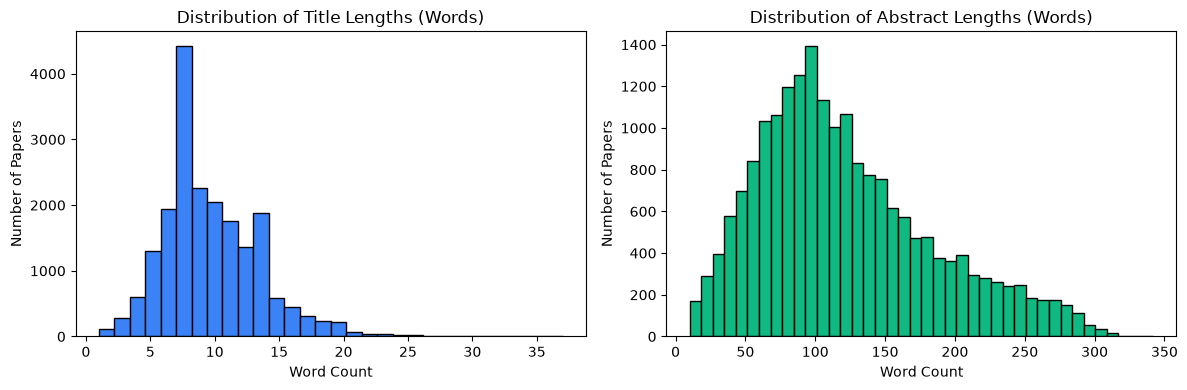

In [2]:
df['title_word_count'] = df['title'].apply(lambda x: len(x.split()))
df['abstract_word_count'] = df['abstract'].apply(lambda x: len(x.split()))

print("=== Title Word Count Statistics ===")
print(df['title_word_count'].describe())

print("\n=== Abstract Word Count Statistics ===")
print(df['abstract_word_count'].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['title_word_count'], bins=30, color='#3b82f6', edgecolor='black')
axes[0].set_title("Distribution of Title Lengths (Words)")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Number of Papers")

axes[1].hist(df['abstract_word_count'], bins=40, color='#10b981', edgecolor='black')
axes[1].set_title("Distribution of Abstract Lengths (Words)")
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("Number of Papers")
plt.tight_layout()
plt.show()

## 2. Subject Category Breakdown

Distribution of arXiv preprint submission batches:
year_month
0705    4675
0707    4674
0706    4479
0704    3990
0708    2182
Name: count, dtype: int64


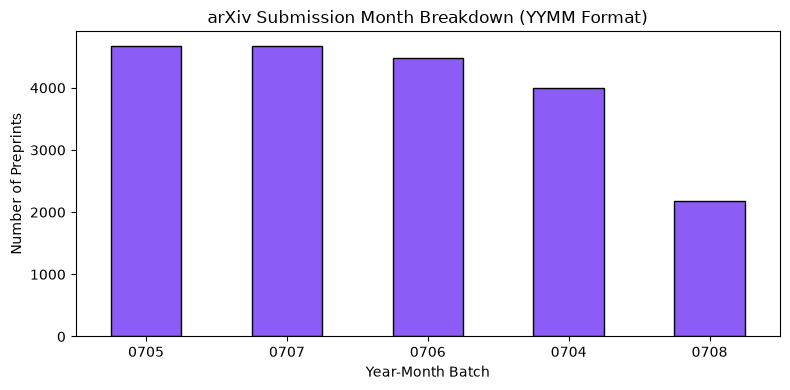

In [3]:
# Analyze paper identifiers and chronological distribution
df["year_month"] = df["id"].astype(str).str.split(".").str[0]
ym_counts = df["year_month"].value_counts().head(10)
print("Distribution of arXiv preprint submission batches:")
print(ym_counts)

plt.figure(figsize=(8, 4))
ym_counts.plot(kind="bar", color="#8b5cf6", edgecolor="black")
plt.title("arXiv Submission Month Breakdown (YYMM Format)")
plt.xlabel("Year-Month Batch")
plt.ylabel("Number of Preprints")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Qualitative Retrieval Comparison: BM25 vs. Dense vs. Hybrid

In [4]:
# Initialize retrievers
bm25 = get_retriever('bm25')
dense = get_retriever('dense')
hybrid = get_retriever('hybrid', bm25_retriever=bm25, dense_retriever=dense)

test_query = "reinforcement learning for robotic control"
print(f"Retrieving for query: '{test_query}'\n")

def print_top_results(name, results):
    print(f"--- {name} (Top 2) ---")
    for r in results[:2]:
        print(f"[{r['rank']}] {r['title']} (Score: {r['score']:.4f})")
        print(f"    {r['abstract'][:140]}...\n")

print_top_results("BM25 Lexical Retriever", bm25.retrieve(test_query, top_k=2))
print_top_results("Dense FAISS Retriever", dense.retrieve(test_query, top_k=2))
print_top_results("Hybrid RRF Retriever", hybrid.retrieve(test_query, top_k=2))

2026-10-24 04:12:39,666 [INFO] Loading docstore from /home/srinivas/.gemini/antigravity/scratch/paper-rag/indices/docstore.parquet...


2026-10-24 04:12:39,809 [INFO] Loading fast bm25s index from /home/srinivas/.gemini/antigravity/scratch/paper-rag/indices/bm25s...


2026-10-24 04:12:42,489 [INFO] HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2 "HTTP/1.1 200 OK"


2026-10-24 04:12:42,493 [INFO] Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

...

--- Dense FAISS Retriever (Top 2) ---
[1] Universal Reinforcement Learning (Score: 0.4764)
    We consider an agent interacting with an unmodeled environment. At each time, the agent makes an observation, takes an action, and incurs a ...

[2] Challenges and Opportunities of Evolutionary Robotics (Score: 0.4275)
    Robotic hardware designs are becoming more complex as the variety and number of on-board sensors increase and as greater computational power...



Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Split strings:   0%|          | 0/1 [00:00<?, ?it/s]

BM25S Retrieve:   0%|          | 0/1 [00:00<?, ?it/s]

--- Hybrid RRF Retriever (Top 2) ---
[1] Universal Reinforcement Learning (Score: 0.0162)
    We consider an agent interacting with an unmodeled environment. At each time, the agent makes an observation, takes an action, and incurs a ...

[2] Design, Implementation, and Cooperative Coevolution of an Autonomous/ Teleoperated Control System for a Serpentine Robotic Manipulator (Score: 0.0161)
    Design, implementation, and machine learning issues associated with developing a control system for a serpentine robotic manipulator are exp...

